# Week 1 - Day 5
# Task 1 - Data Cleaning

## Employee Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All libraries imported successfully")

All libraries imported successfully


In [3]:
# Load employee dataset

df = pd.read_csv("../data/employees.csv")

# Display first five records

df.head()

,id,name,department,salary
0,1,Arun,IT,55000
1,2,Priya,HR,42000
2,3,Karthik,Finance,48000
3,4,Divya,IT,62000
4,5,Ravi,Sales,40000


In [4]:
print("Original Dataset Information")

# Check rows and columns
print("Rows and Columns:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check data types
print("\nData Types:")
print(df.dtypes)

Original Dataset Information
Rows and Columns: (20, 4)

Missing Values:
id            0
name          0
department    0
salary        0
dtype: int64

Duplicate Records:
0

Data Types:
id            int64
name            str
department      str
salary        int64
dtype: object


In [5]:
# Check missing values before cleaning

print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill numerical columns with median

numeric_columns = df.select_dtypes(
    include=np.number
).columns

for col in numeric_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Fill categorical columns with mode

categorical_columns = df.select_dtypes(
    include="object"
).columns

for col in categorical_columns:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
id            0
name          0
department    0
salary        0
dtype: int64

Missing values after cleaning:
id            0
name          0
department    0
salary        0
dtype: int64


C:\Users\dell\AppData\Local\Temp\ipykernel_1252\896414143.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [6]:
print("Data types before correction:")
print(df.dtypes)

Data types before correction:
id            int64
name            str
department      str
salary        int64
dtype: object


In [7]:
if "joining_date" in df.columns:
    df["joining_date"] = pd.to_datetime(
        df["joining_date"],
        errors="coerce"
    )

In [8]:
if "salary" in df.columns:
    df["salary"] = pd.to_numeric(
        df["salary"],
        errors="coerce"
    )

In [9]:
print("Duplicates before cleaning:")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("\nDuplicates after cleaning:")
print(df.duplicated().sum())

Duplicates before cleaning:
0

Duplicates after cleaning:
0


In [10]:
for col in df.select_dtypes(include="object").columns:

    df[col] = df[col].str.strip()

    df[col] = df[col].str.title()

print("Text standardisation completed")

df.head()

Text standardisation completed


C:\Users\dell\AppData\Local\Temp\ipykernel_1252\1727442971.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


,id,name,department,salary
0,1,Arun,It,55000
1,2,Priya,Hr,42000
2,3,Karthik,Finance,48000
3,4,Divya,It,62000
4,5,Ravi,Sales,40000


In [11]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print("\nColumn:", col)
    print("Outliers:", len(outliers))


Column: id
Outliers: 0

Column: salary
Outliers: 0


In [12]:
original_df = pd.read_csv("../data/employees.csv")

summary = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Missing Values",
        "Duplicate Records"
    ],

    "Before Cleaning": [
        len(original_df),
        original_df.isnull().sum().sum(),
        original_df.duplicated().sum()
    ],

    "After Cleaning": [
        len(df),
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
})

summary

,Metric,Before Cleaning,After Cleaning
0,Total Rows,20,20
1,Missing Values,0,0
2,Duplicate Records,0,0


In [13]:
df.to_csv("../data/clean_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


# Task 2 - Exploratory Data Analysis (EDA)

## Employee Data Analysis

In [14]:
# Load cleaned employee dataset

df = pd.read_csv("../data/clean_data.csv")

# Display first five records

df.head()

,id,name,department,salary
0,1,Arun,It,55000
1,2,Priya,Hr,42000
2,3,Karthik,Finance,48000
3,4,Divya,It,62000
4,5,Ravi,Sales,40000


In [15]:
# Calculate summary statistics

df.describe()

,id,salary
count,20.00000,20.000000
mean,10.50000,50700.000000
std,5.91608,7392.029847
min,1.00000,40000.000000
25%,5.75000,44750.000000
50%,10.50000,49500.000000
75%,15.25000,56250.000000
max,20.00000,65000.000000


In [16]:
df.describe(include="object")

C:\Users\dell\AppData\Local\Temp\ipykernel_1252\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,name,department
count,20,20
unique,20,4
top,Arun,It
freq,1,6


In [17]:
print(df.columns.tolist())

['id', 'name', 'department', 'salary']


In [18]:
# Compare average salary by department

department_analysis = df.groupby("department")["salary"].agg(
    ["mean", "median", "min", "max", "count"]
)

print(department_analysis)

               mean   median    min    max  count
department                                       
Finance     52000.0  52000.0  48000  56000      5
Hr          44500.0  44500.0  42000  47000      4
It          59500.0  59000.0  55000  65000      6
Sales       43800.0  43000.0  40000  49000      5


In [19]:
# Count employees in each department

department_count = df.groupby("department").size()

print(department_count)

department
Finance    5
Hr         4
It         6
Sales      5
dtype: int64


In [20]:
# Select numerical columns

numeric_df = df.select_dtypes(include=np.number)

# Calculate correlation

correlation = numeric_df.corr()

print(correlation)

             id   salary
id      1.00000  0.11313
salary  0.11313  1.00000


In [21]:
# Find the top 3 correlations

corr_pairs = correlation.unstack()

corr_pairs = corr_pairs[
    corr_pairs.index.get_level_values(0) <
    corr_pairs.index.get_level_values(1)
]

top_three = corr_pairs.reindex(
    corr_pairs.abs().sort_values(ascending=False).index
).head(3)

print("Top 3 Correlations:")
print(top_three)

Top 3 Correlations:
id  salary    0.11313
dtype: float64


## Business Questions

1. Which department has the highest average salary?
2. Which department has the highest number of employees?
3. What is the average employee salary?
4. What is the minimum and maximum salary?
5. Which numerical columns have the strongest correlation?

In [22]:
# Question 1
print("Department with highest average salary:")
print(df.groupby("department")["salary"].mean().idxmax())

# Question 2
print("\nDepartment with highest employee count:")
print(df["department"].value_counts().idxmax())

# Question 3
print("\nAverage employee salary:")
print(df["salary"].mean())

# Question 4
print("\nMinimum salary:", df["salary"].min())
print("Maximum salary:", df["salary"].max())

# Question 5
print("\nTop 3 correlations:")
print(top_three)

Department with highest average salary:
It

Department with highest employee count:
It

Average employee salary:
50700.0

Minimum salary: 40000
Maximum salary: 65000

Top 3 correlations:
id  salary    0.11313
dtype: float64


In [23]:
# Create department budget dataset

department_budget = pd.DataFrame({
    "department": [
        "Hr",
        "It",
        "Finance",
        "Sales",
        "Marketing"
    ],

    "budget": [
        500000,
        800000,
        600000,
        700000,
        450000
    ]
})

# Merge employee data with department budget

merged_df = pd.merge(
    df,
    department_budget,
    on="department",
    how="left"
)

merged_df.head()

,id,name,department,salary,budget
0,1,Arun,It,55000,800000
1,2,Priya,Hr,42000,500000
2,3,Karthik,Finance,48000,600000
3,4,Divya,It,62000,800000
4,5,Ravi,Sales,40000,700000


In [24]:
merged_df.to_csv(
    "../data/merged_employee_data.csv",
    index=False
)

print("Merged dataset saved successfully!")

Merged dataset saved successfully!


In [25]:
pivot_table = pd.pivot_table(
    df,
    index="department",
    values="salary",
    aggfunc=["mean", "min", "max", "count"]
)

print(pivot_table)

               mean    min    max  count
             salary salary salary salary
department                              
Finance     52000.0  48000  56000      5
Hr          44500.0  42000  47000      4
It          59500.0  55000  65000      6
Sales       43800.0  40000  49000      5


# Task 3 - Five Visualisations

## Employee Data Visualisation

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv("../data/clean_data.csv")

# Create figures folder
os.makedirs("../reports/figures", exist_ok=True)

print("Dataset loaded successfully")
print(df.columns.tolist())

Dataset loaded successfully
['id', 'name', 'department', 'salary']


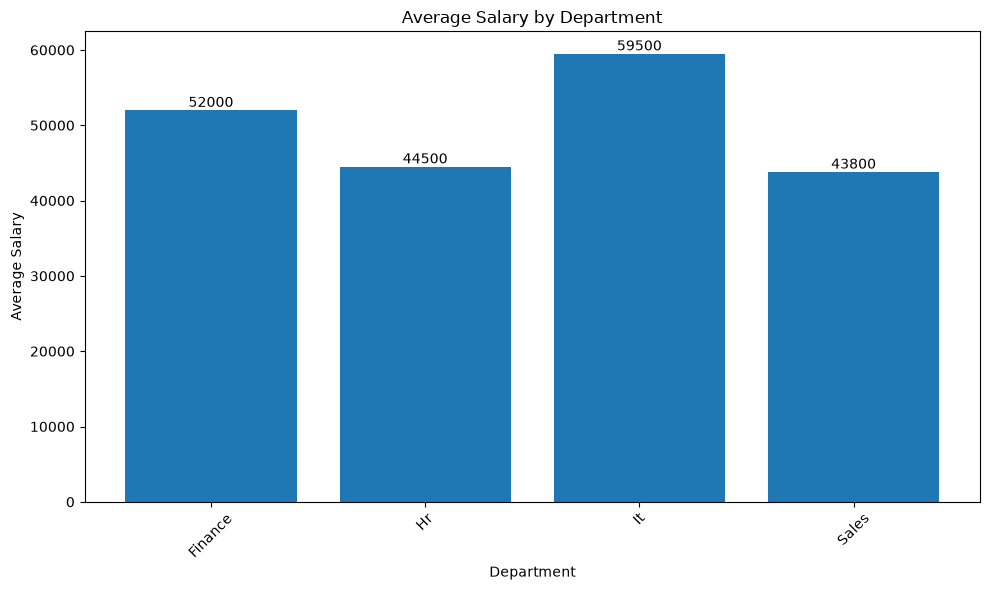

In [27]:
avg_salary = df.groupby("department")["salary"].mean()

plt.figure(figsize=(10, 6))

bars = plt.bar(avg_salary.index, avg_salary.values)

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")

plt.xticks(rotation=45)
plt.bar_label(bars, fmt="%.0f")

plt.tight_layout()

plt.savefig("../reports/figures/bar_chart.png")

plt.show()

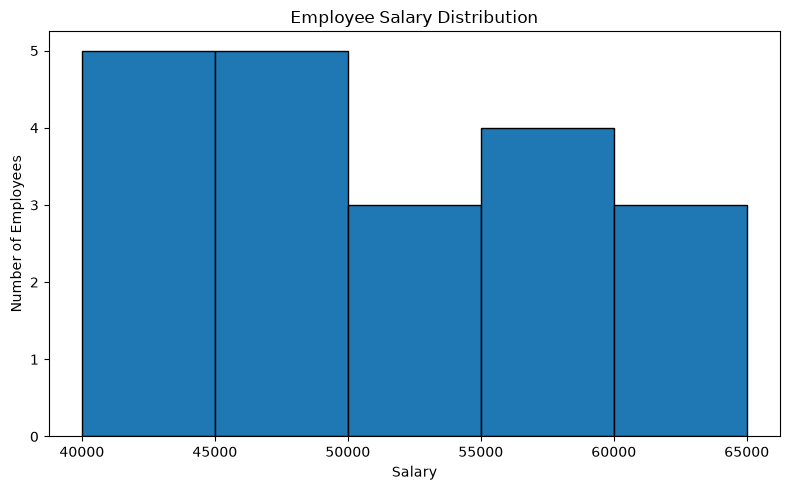

In [28]:
plt.figure(figsize=(8, 5))

plt.hist(df["salary"].dropna(), bins=5, edgecolor="black")

plt.title("Employee Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")

plt.tight_layout()

plt.savefig("../reports/figures/histogram.png")

plt.show()

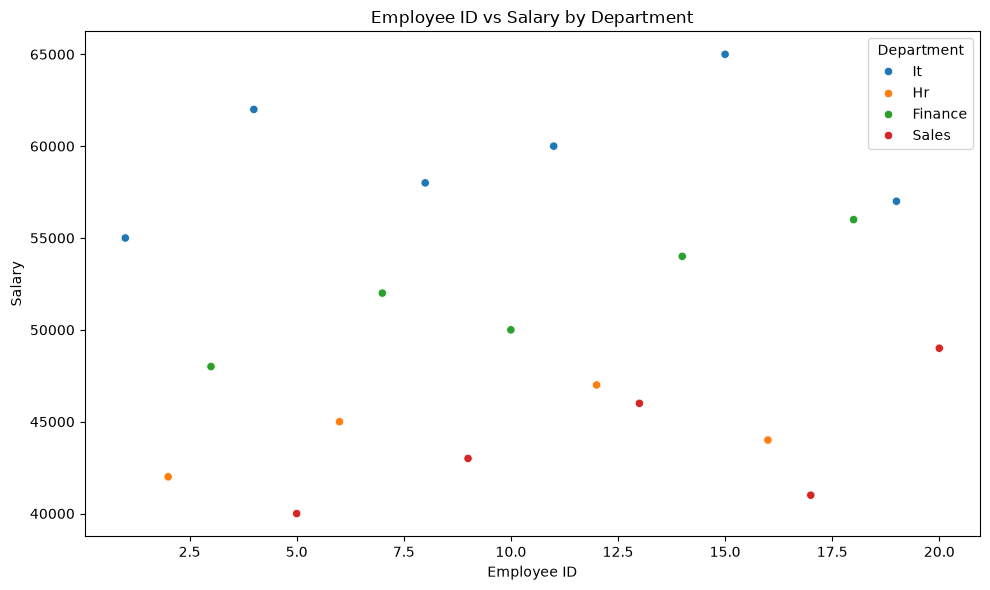

In [29]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="id",
    y="salary",
    hue="department"
)

plt.title("Employee ID vs Salary by Department")
plt.xlabel("Employee ID")
plt.ylabel("Salary")

plt.legend(title="Department")

plt.tight_layout()

plt.savefig("../reports/figures/scatter_plot.png")

plt.show()

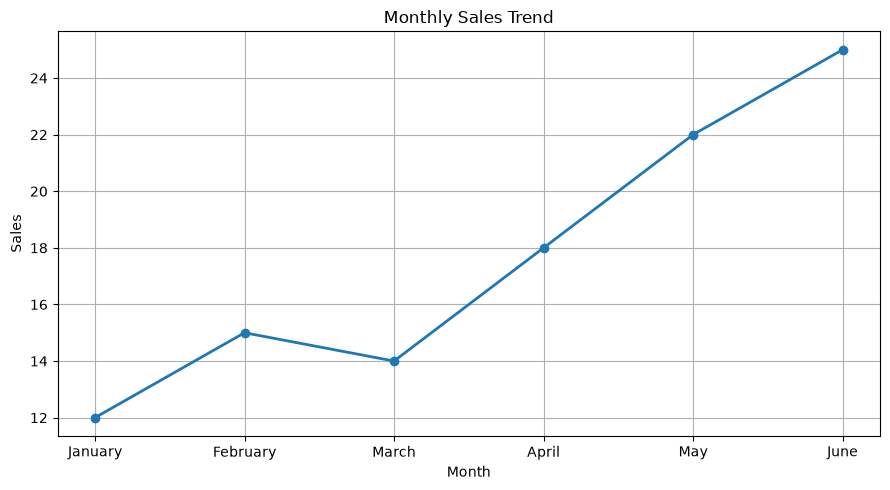

In [30]:
months = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June"
]

sales = [12, 15, 14, 18, 22, 25]

plt.figure(figsize=(9, 5))

plt.plot(
    months,
    sales,
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.grid(True)

plt.tight_layout()

plt.savefig("../reports/figures/line_chart.png")

plt.show()

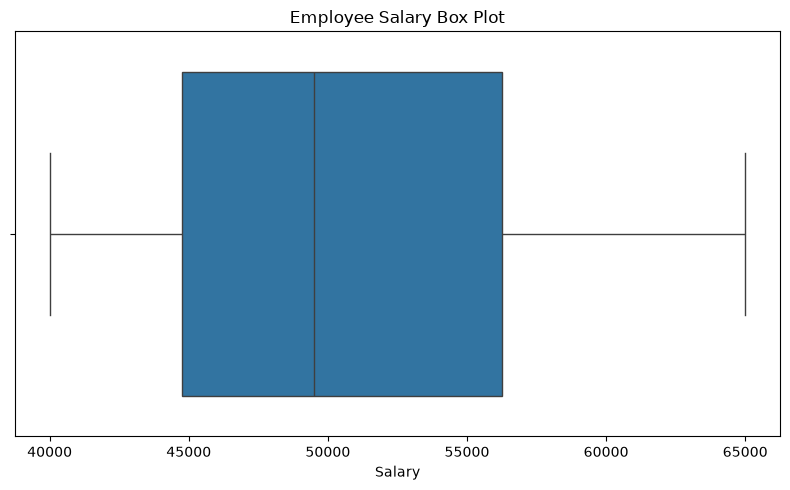

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["salary"])

plt.title("Employee Salary Box Plot")
plt.xlabel("Salary")

plt.tight_layout()

plt.savefig("../reports/figures/box_plot.png")

plt.show()

# Task 4 - Report and Presentation